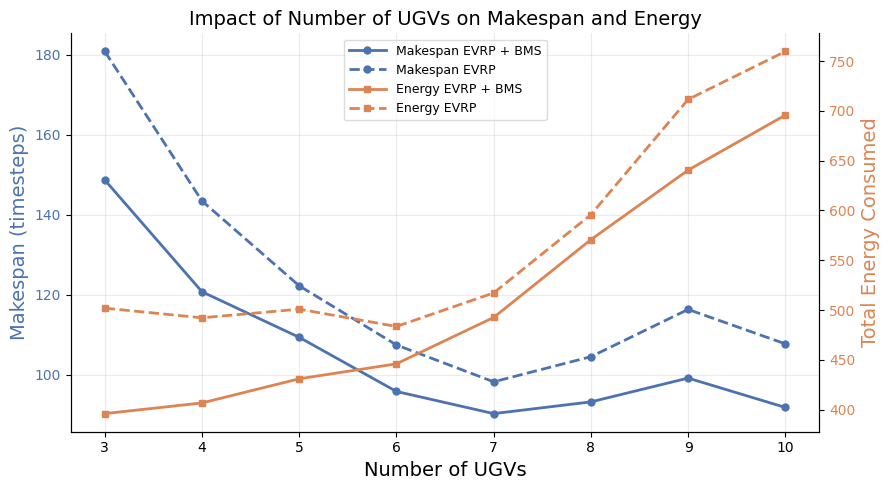

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

# ── Configure here ────────────────────────────────────────────────────────────
results_file = "runs/iros_26/results_nrlp.csv"
param        = "num_evs"    # x-axis: num_tasks | ev_range | maze_loop_percentage | num_evs
algo         = "evrp"           # filter: "mtsp" | "evrp" | None (aggregate both)
# ─────────────────────────────────────────────────────────────────────────────

param_labels = {
    'num_tasks':             'Number of Tasks',
    'ev_range':              'UGV Range',
    'maze_loop_percentage':  'Maze Loop %',
    'num_evs':               'Number of UGVs',
}

df = pd.read_csv(results_file)
df = df[df["ev_range"] <= 4000]  # Filter out outliers for better visualization
df['energy'] = df['ev_distance'] + 0.01 * df['drone_distance']

if algo is not None:
    df = df[df['algo'] == algo]

algo_title = algo.upper() if algo else 'All Algos'

# bms=1 → solid, bms=0 → dashed
methods = [
    (1, '+ BMS',    '-'),
    (0, ' ', '--'),
]

makespan_color = '#4C72B0'   # blue
energy_color   = '#DD8452'   # orange

fig, ax1 = plt.subplots(figsize=(9, 5))
ax2 = ax1.twinx()

for bms_val, lbl, ls in methods:
    g = df[df['bms'] == bms_val].groupby(param)[['timesteps', 'energy']].mean().reset_index()

    ax1.plot(g[param], g['timesteps'],
             marker='o', linestyle=ls, color=makespan_color,
             linewidth=2, markersize=5, label=f'Makespan {algo.upper()} {lbl}')

    ax2.plot(g[param], g['energy'],
             marker='s', linestyle=ls, color=energy_color,
             linewidth=2, markersize=5, label=f'Energy {algo.upper()} {lbl}')

ax1.set_xlabel(param_labels.get(param, param), fontsize=14)
ax1.set_ylabel('Makespan (timesteps)', color=makespan_color, fontsize=14)
ax1.tick_params(axis='y', labelcolor=makespan_color)

ax2.set_ylabel('Total Energy Consumed', color=energy_color, fontsize=14)
ax2.tick_params(axis='y', labelcolor=energy_color)

ax1.spines[['top']].set_visible(False)
ax2.spines[['top']].set_visible(False)
ax1.grid(True, alpha=0.25)

# Combined legend
lines1, labs1 = ax1.get_legend_handles_labels()
lines2, labs2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labs1 + labs2, fontsize=9, loc='upper center', framealpha=0.7, handlelength=3)

plt.title(f'Impact of {param_labels.get(param, param)} on Makespan and Energy', fontsize=14)
plt.tight_layout()
plt.show()


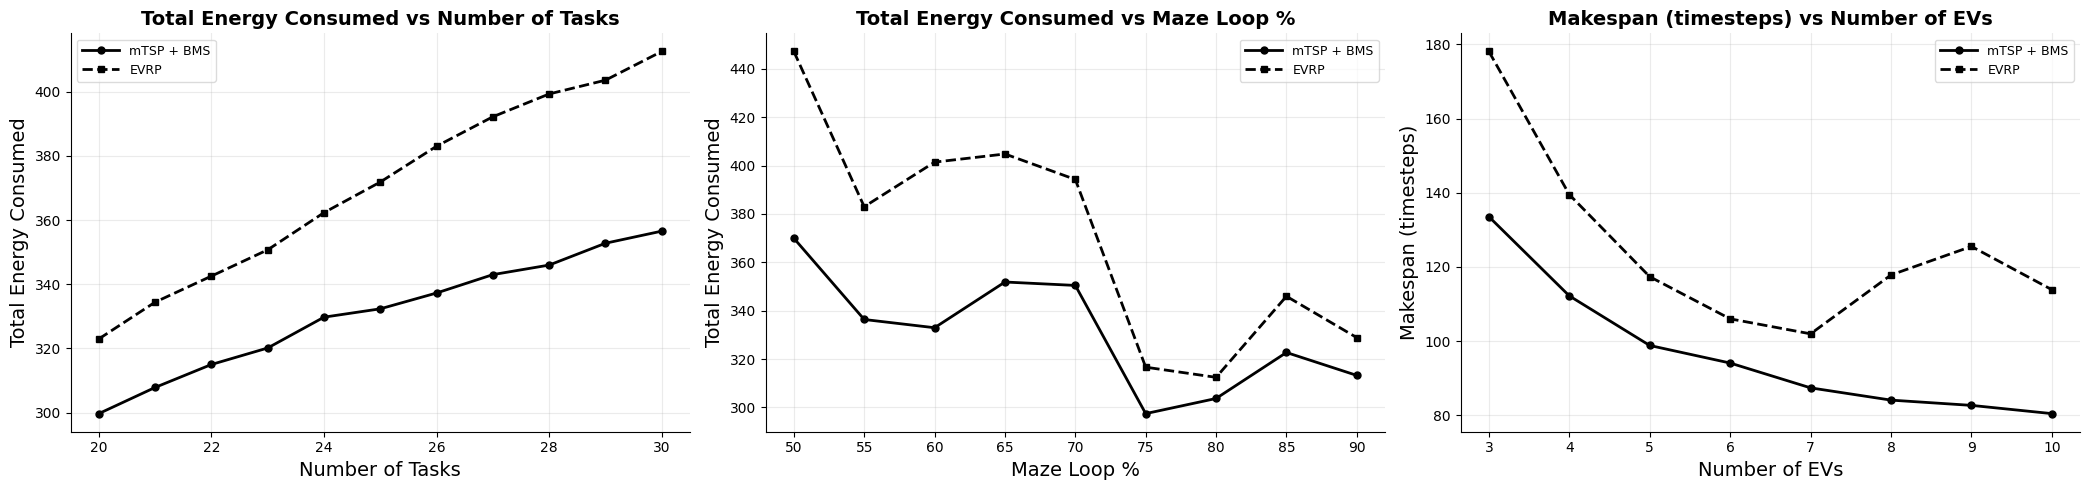

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

param_labels = {
    'num_tasks':             'Number of Tasks',
    'ev_range':              'EV Range',
    'maze_loop_percentage':  'Maze Loop %',
    'num_evs':               'Number of EVs',
}
metric_labels = {
    'timesteps':             'Makespan (timesteps)',
    'energy':                'Total Energy Consumed',
    'num_tasks_finished':    'Tasks Finished',
    'ev_distance':           'EV Distance',
}

methods = [
    # ('mtsp', 0, 'mTSP',       '#4C72B0', 'o', '-'),
    ('mtsp', 1, 'mTSP + BMS', 'k', 'o', '-'),
    ('evrp', 0, 'EVRP',       'k', 's', '--'),
    # ('evrp', 1, 'EVRP + BMS', '#DD8452', 's', '--'),
]

# (results_file, param, metric)
plots = [
    ("runs/iros_26/results.csv",      'num_tasks',            'energy'),
    ("runs/iros_26/results.csv",      'maze_loop_percentage', 'energy'),
    ("runs/iros_26/results_nrlp.csv", 'num_evs',              'timesteps'),
]

fig, axs = plt.subplots(1, 3, figsize=(21, 5))

for ax, (results_file, param, metric) in zip(axs, plots):
    df = pd.read_csv(results_file)
    df['energy'] = df['ev_distance'] + 0.01 * df['drone_distance']

    for algo, bms_val, lbl, color, mk, ls in methods:
        sub = df[(df['algo'] == algo) & (df['bms'] == bms_val)]
        g = sub.groupby(param)[metric].mean().reset_index()
        ax.plot(g[param], g[metric],
                marker=mk, linestyle=ls, color=color,
                linewidth=2, markersize=5, label=lbl)

    ax.set_xlabel(param_labels.get(param, param), fontsize=14)
    ax.set_ylabel(metric_labels.get(metric, metric), fontsize=14)
    ax.set_title(f'{metric_labels.get(metric, metric)} vs {param_labels.get(param, param)}',
                 fontsize=14, fontweight='bold')
    ax.spines[['top', 'right']].set_visible(False)
    ax.grid(True, alpha=0.25)

    ax.legend(fontsize=9, framealpha=0.7, handlelength=3)

plt.tight_layout()
plt.show()


In [ ]:

import pandas as pd

# ── Configure here ────────────────────────────────────────────────────────────
results_file = "runs/iros_26/results.csv"

# Define algo A and algo B as (algo, bms) tuples
# algo: "mtsp" | "evrp"
# bms:  0 (no BMS) | 1 (with BMS)
algo_a = ("evrp", 0)   # e.g. EVRP
algo_b = ("mtsp", 1)   # e.g. EVRP + BMS
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(results_file)
df['energy'] = df['ev_distance'] + 0.01 * df['drone_distance']

label_map = {("mtsp", 0): "mTSP", ("mtsp", 1): "mTSP + BMS",
             ("evrp", 0): "EVRP", ("evrp", 1): "EVRP + BMS"}

lbl_a = label_map.get(algo_a, str(algo_a))
lbl_b = label_map.get(algo_b, str(algo_b))

sub_a = df[(df['algo'] == algo_a[0]) & (df['bms'] == algo_a[1])]
sub_b = df[(df['algo'] == algo_b[0]) & (df['bms'] == algo_b[1])]

results = {}
for metric in ['timesteps', 'energy']:
    mean_a = sub_a[metric].mean()
    mean_b = sub_b[metric].mean()
    # Percent difference relative to algo_a: (b - a) / a * 100
    pct_diff = (mean_b - mean_a) / mean_a * 100
    results[metric] = {'mean_a': mean_a, 'mean_b': mean_b, 'pct_diff': pct_diff}

print(f"{'Metric':<20} {lbl_a:>18} {lbl_b:>18} {'% Diff (B vs A)':>18}")
print("-" * 76)
for metric, vals in results.items():
    label = 'Makespan' if metric == 'timesteps' else 'Energy'
    sign = '+' if vals['pct_diff'] >= 0 else ''
    print(f"{label:<20} {vals['mean_a']:>18.3f} {vals['mean_b']:>18.3f} {sign}{vals['pct_diff']:>17.2f}%")


Metric                             EVRP         mTSP + BMS    % Diff (B vs A)
----------------------------------------------------------------------------
Makespan                        109.172            102.095             -6.48%
Energy                          370.520            330.954            -10.68%
